# Exercise 2

In [1]:
import tensorflow as tf
from autograd import numpy as np
import pandas as pd

from tensorflow.keras.datasets import mnist
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

In [2]:
train_labels.shape=(1,60000)
test_labels.shape=(1,10000)
train_images=(train_images.reshape(60000,784)).T
test_images=(test_images.reshape(10000,784)).T
print(train_images.shape)
print(test_images.shape)
print(train_labels.shape)
print(test_labels.shape)
print(train_images.dtype)
print(train_labels.dtype)

(784, 60000)
(784, 10000)
(1, 60000)
(1, 10000)
uint8
uint8


In [3]:
# compute C linear combinations of input point, one per classifier
def model(x,w):
    a = w[0] + np.dot(x.T,w[1:])
    return a.T

# multiclass perceptron
def multiclass_perceptron(w,x,y,iter):
    # get subset of points
    x_p = x[:,iter]
    y_p = y[:,iter]

    # pre-compute predictions on all points
    all_evals = model(x_p,w)

    # compute maximum across data points
    a =  np.max(all_evals,axis = 0)        

    # compute cost in compact form using numpy broadcasting
    b = all_evals[y_p.astype(int).flatten(),np.arange(np.size(y_p))]
    cost = np.sum(a - b)

    # return average
    return cost/float(np.size(y_p))

In [4]:
from autograd.misc.flatten import flatten_func
from autograd import grad as gradient 

# minibatch gradient descent
def gradient_descent(g,w,x_train,y_train,alpha,max_its,batch_size):
    # Number of batches needed
    num_train = x_train.shape[1]
    num_batches = int(np.ceil(np.divide(num_train, batch_size)))
    
    # compute gradient module using autograd
    grad_func = gradient(g)

    all_inds = np.arange(num_train)

    # run the gradient descent loop
    weight_history = [w]
    cost_history = [g(w, x_train, y_train, all_inds)]
    for k in range(max_its):
        for b in range(num_batches):
            
            batch_inds = np.arange(b*batch_size, min((b+1)*batch_size, num_train))
            grad_eval = grad_func(w, x_train, y_train, batch_inds)
            
            w = w - alpha*grad_eval
    
        weight_history.append(w)
        cost_history.append(g(w, x_train, y_train, all_inds))
    return cost_history, weight_history

# 2.2

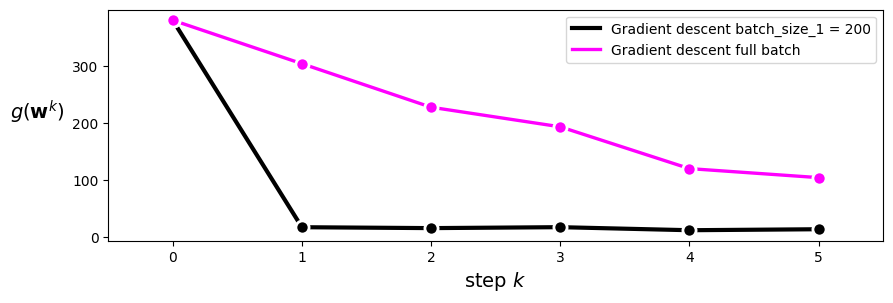

In [5]:
max_its = 5
N = train_images.shape[0]  # 784 features, pas train_labels.shape[1]
C = 10
w = 0.1*np.random.randn(N+1, C) 
alpha = 0.001
batch_size_1 = 200
batch_size_2 = train_images.shape[1]  # 60000 samples
cost_history_1, weight_history_1 = gradient_descent(multiclass_perceptron,w,train_images,train_labels,alpha,max_its,batch_size_1)
cost_history_2, weight_history_2 = gradient_descent(multiclass_perceptron,w,train_images,train_labels,alpha,max_its,batch_size_2)
# plot
from MLRPlotting import static_plotter
static_plotter = static_plotter.Visualizer()
static_plotter.plot_cost_histories([cost_history_1, cost_history_2],start=0,points=True,labels=[r'Gradient descent batch_size_1 = 200', r'Gradient descent full batch'])

The 200 batch_size performed clearly better (min_cost = 11) compared to the full batch (min_cost = 99).

# 2.3

In [6]:
best_w = weight_history_1[-1]
pred = model(train_images, best_w)
pred.shape

(10, 60000)

In [7]:
def miscount(w, x, y):
    miscounts = {}
    for i in range(10):
        i_ind = np.argwhere(y.flatten() == i).flatten()
        n_i = len(i_ind)
        preds = np.argmax(model(x[:, i_ind], w), axis=0)
        miscounts[i] = np.sum(preds != i) * 100 / n_i
    return miscounts

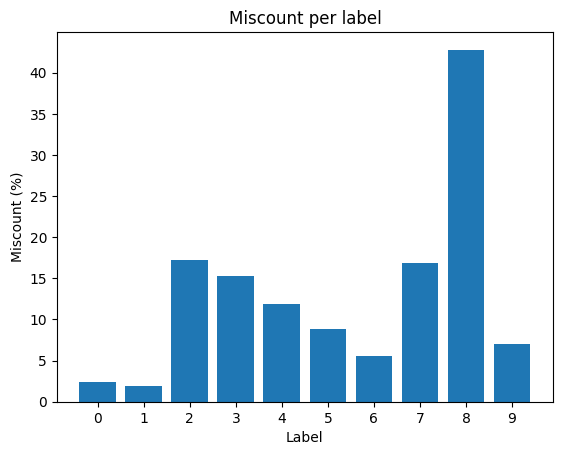

In [8]:
d = miscount(best_w, train_images, train_labels)
miscounts = [d[i] for i in range(10)]

import matplotlib.pyplot as plt
plt.bar(np.arange(0, 10), miscounts)
plt.xlabel("Label")
plt.ylabel("Miscount (%)")
plt.title("Miscount per label")
plt.xticks(np.arange(0, 10))
plt.show()

Number 8 is by far the most misclassified digit.